In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_patches import DataLoaderPatches
import project_images_loader as pil
import matplotlib.pyplot as plt

import discriminator_IN as Discriminator
import generator_IN as Generator

from layers.Wavelet3D_16 import DWT3D

import utils.functions as fc
import utils.util_deep_learning as udl
import utils.visualization as vis
import utils.util as util
import utils.patches_controller as patches_controller
import utils.util_freesurfer_segmentation as ufs

from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')
print(tf.config.list_physical_devices('GPU'))



2024-05-02 11:38:35.455429: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F AVX512_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-02 11:38:40.927585: I tensorflow/core/util/util.cc:169] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-05-02 11:38:43.819480: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-05-02 11:39:04.681646: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; 

SERVER: True


/cluster/home/agustinc/miniconda3/envs/s4_old/lib/python3.9/site-packages/tensorflow_addons/utils/tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(
/cluster/home/agustinc/miniconda3/envs/s4_old/lib/python3.9/site-packages/tensorflow_addons/utils/ensure_tf_install.py:53: UserWarning: Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.13.0 and strictly below 2.16.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.10.1 and is not supported. 
Some things might work, some things might not.
If you were to enco

INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA A100-PCIE-40GB, compute capability 8.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Visualize data

In [2]:

# # # %matplotlib widget

# data_train = DataLoaderPatches(pil.INAME_PREPROCESSED,
#                                 batch_size=1, 
#                                 image_size=(192, 224, 192), 
#                                 patch_size=(64, 64, 64),
#                                 patch_step=(32,32,32),
#                                 images_onmemory=1,
#                                 shuffle_patches=True,
#                                 channels_first=False,
#                                 background_th=0.75,
#                                 shuffle_images=True,
#                                 nb_patients=5,
#                                 )

# data_train.prepare_custom_patches("seg3", pil.INAME_SEGMENTATION.format("{0}", "{1}", 3, "nii.gz"))
# data_train.prepare_custom_patches("bmask", pil.INAME_BRAIN_MASK.format("{0}", "{1}", pil.REGISTRATION_TO_MNI))

# # batch_patches = data_train[0]
# # iter_custom_patches = data_train.get_iter_custom_patches("seg3")

# # # fc.imgshow_3D("", batch_patches[0][0,...,0], current_plane=32, range_values=[0,1])
# # # fc.imgshow_3D("", iter_custom_patches[0][0,...,0], current_plane=32, range_values=[0,3])

# def show_2(img1, img2):
#     fig, ax = plt.subplots(1,2)
#     fc.imgshow_matplotlib("", img1[0,...,32,0], subplot=ax[0])
#     fc.imgshow_matplotlib("", img2[0,...,32,0], subplot=ax[1])
#     plt.show()

# weights={"bg":0, "ext":0.5, "csf":2, "gm":3, "wm":1}
# for i in range(2):
#     for i, (hunt3, hunt4) in enumerate(data_train):
#         if i == 0:
#             # custom_hunt3, custom_hunt4 = data_train.get_iter_custom_patches("seg3")
#             custom_hunt3, custom_hunt4 = get_weight_mask_hunt4(data_train, weights)
#             show_2(hunt3, custom_hunt3)
#             show_2(hunt4, custom_hunt4)




### Validation visualization

In [3]:

def generate_image_step(img_org, G, patch_size, patch_step, batch_size=20):
    img_patches = patches_controller.extract_patches(img_org, patch_shape=patch_size, extraction_step=patch_step).astype(np.float32)
    gen_patches = np.zeros_like(img_patches)

    for i in tqdm(range(0, len(img_patches), batch_size)):
        patches_batch = np.expand_dims(img_patches[i:min(i+batch_size, len(img_patches))], axis=-1)
        gen_result = G(patches_batch, training=False)
        gen_patches[i:min(i+batch_size, len(img_patches))] = gen_result[-1][..., 0]

    gen_image = patches_controller.perform_voting(gen_patches, 
                                                  patch_shape=patch_size, 
                                                  expected_shape=img_org.shape, 
                                                  extraction_step=patch_step,
                                                  window_sep=patch_step)
    return gen_image


def show_generated_image(id, G_h4, G_h3, patch_size, patch_step, current_plane=116, show=True):
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    img_gen_h4 = generate_image_step(img_hunt3, G_h4, patch_size=patch_size, patch_step=patch_step)
    img_gen_h3 = generate_image_step(img_hunt4, G_h3, patch_size=patch_size, patch_step=patch_step)

    _, _, img_gen_h4 = vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4, current_plane=current_plane, show=show)
    img_hunt3, img_hunt4, img_gen_h3 = vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h3, current_plane=current_plane, show=show)

    return img_hunt3, img_hunt4, img_gen_h4, img_gen_h3



In [4]:
def get_2_scales_reduction(img): 
    img_red = fc.reduce_3D_images_batch(img, scaling_factor=2)
    img_red_red = fc.reduce_3D_images_batch(img_red, scaling_factor=2)
    return img_red, img_red_red

### Loss functions

In [5]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)

def adversarial_loss(disc_h4_real, disc_h3_real, disc_h4_fake, disc_h3_fake):

    real_loss_h3 = cross_entropy(tf.ones_like(disc_h3_real), disc_h3_real)
    real_loss_h4 = cross_entropy(tf.ones_like(disc_h4_real), disc_h4_real)

    fake_loss_h3 = cross_entropy(tf.zeros_like(disc_h3_fake), disc_h3_fake)
    fake_loss_h4 = cross_entropy(tf.zeros_like(disc_h4_fake), disc_h4_fake)

    loss = real_loss_h3 + real_loss_h4 + fake_loss_h3 + fake_loss_h4
    return loss

def quality_loss(target_image, predicted_image, disc_prob, beta=1.5):
    loss = tf.reduce_mean(tf.abs(target_image - predicted_image) * tf.pow(1 - disc_prob, beta))
    return loss

def gram_matrix(input_tensor):
    batch_size, width, height, deep, channels = input_tensor.get_shape().as_list()
    reshaped_tensor = tf.reshape(input_tensor, [batch_size, width * height, deep])
    gram_matrix = tf.matmul(reshaped_tensor, reshaped_tensor, transpose_a=True)
    num_elements = tf.cast(width * height * deep * channels, tf.float32)
    gram_matrix /= num_elements
    return gram_matrix


def texture_loss(target_image, predicted_image):
    gram_real = gram_matrix(target_image)
    gram_fake = gram_matrix(predicted_image)
    
    loss = tf.reduce_mean(tf.square(gram_real - gram_fake))
    
    return loss

dwt3D_layer = DWT3D(wavelet_name="bior1.3")
def frequency_loss(target_image, predicted_image):
    dwt_target_image = dwt3D_layer(target_image)
    dwt_predicted_image = dwt3D_layer(predicted_image)
    loss = tf.reduce_mean(tf.abs(dwt_target_image - dwt_predicted_image))
    return tf.cast(loss, tf.float32)

def calc_cycle_loss(target_image, cycled_image):
    loss1 = tf.reduce_mean(tf.abs(target_image - cycled_image))
    return loss1


def segmentation_dice_loss(batch_seg, batch_y_pred, means, stds, classs_weights, class_imbalance=None,  dtype=tf.float32):
    dice_loss = []
    for i in range(batch_seg.shape[0]):
        _dice_loss = (udl.gmm_dice_loss(tf.squeeze(batch_seg[i]), 
                                            tf.squeeze(batch_y_pred[i]), 
                                            means[i], 
                                            stds[i], 
                                            classs_weights[i], 
                                            dtype=dtype))
        # if class_imbalance is not None:
        #     _dice_loss = _dice_loss * class_imbalance[i]

        dice_loss.append(_dice_loss)
        
    dice_loss = tf.convert_to_tensor(dice_loss)
    return tf.reduce_mean(dice_loss, axis=[0,1])

2024-05-02 11:40:27.231575: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F AVX512_VNNI FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-02 11:40:35.447169: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1616] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38206 MB memory:  -> device: 0, name: NVIDIA A100-PCIE-40GB, pci bus id: 0000:14:00.0, compute capability: 8.0


In [6]:
def apply_mask(image, seg):
    return tf.where(seg > 0, image, tf.zeros_like(image))

@tf.function
def train_step(G_h3, D_h3, G_h4, D_h4, h3_batch, h4_batch, g_h3_optimizer, d_h3_optimizer, g_h4_optimizer, d_h4_optimizer, h3_seg, h4_seg, h3_gmm, h4_gmm):
    with tf.GradientTape() as g_h4_tape, tf.GradientTape() as d_h4_tape, tf.GradientTape() as g_h3_tape, tf.GradientTape() as d_h3_tape:
        h3_batch_1, h3_batch_2, h3_batch_3 = h3_batch
        h4_batch_1, h4_batch_2, h4_batch_3 = h4_batch

        h3_seg_1, h3_seg_2, h3_seg_3 = h3_seg
        h4_seg_1, h4_seg_2, h4_seg_3 = h4_seg
        
        
        h4_fake1, h4_fake2, h4_fake3  = G_h4(h3_batch_3, training=True)
        h3_fake1_cyc, h3_fake2_cyc, h3_fake3_cyc = G_h3(h4_fake3, training=True)

        h3_fake1, h3_fake2, h3_fake3  = G_h3(h4_batch_3, training=True)
        h4_fake1_cyc, h4_fake2_cyc, h4_fake3_cyc = G_h4(h3_fake3, training=True)
        

        disc_h4_real1, disc_h4_real2, disc_h4_real3 = D_h4(h4_batch_3, training=True)
        disc_h4_fake1, disc_h4_fake2, disc_h4_fake3 = D_h4(h4_fake3, training=True)

        disc_h3_real1, disc_h3_real2, disc_h3_real3 = D_h3(h3_batch_3, training=True)
        disc_h3_fake1, disc_h3_fake2, disc_h3_fake3 = D_h3(h3_fake3, training=True)
        

        # ---- apply masks
        # original images
        h4_batch_3 = apply_mask(h4_batch_3, h4_seg_3)
        h4_batch_2 = apply_mask(h4_batch_2, h4_seg_2)
        h4_batch_1 = apply_mask(h4_batch_1, h4_seg_1)

        h3_batch_3 = apply_mask(h3_batch_3, h3_seg_3)
        h3_batch_2 = apply_mask(h3_batch_2, h3_seg_2)
        h3_batch_1 = apply_mask(h3_batch_1, h3_seg_1)

        # fake images
        h4_fake3 = apply_mask(h4_fake3, h4_seg_3)
        h4_fake2 = apply_mask(h4_fake2, h4_seg_2)
        h4_fake1 = apply_mask(h4_fake1, h4_seg_1)

        h3_fake3 = apply_mask(h3_fake3, h3_seg_3)
        h3_fake2 = apply_mask(h3_fake2, h3_seg_2)
        h3_fake1 = apply_mask(h3_fake1, h3_seg_1)

        # cycled images
        h4_fake3_cyc = apply_mask(h4_fake3_cyc, h4_seg_3)
        h4_fake2_cyc = apply_mask(h4_fake2_cyc, h4_seg_2)
        h4_fake1_cyc = apply_mask(h4_fake1_cyc, h4_seg_1)

        h3_fake3_cyc = apply_mask(h3_fake3_cyc, h3_seg_3)
        h3_fake2_cyc = apply_mask(h3_fake2_cyc, h3_seg_2)
        h3_fake1_cyc = apply_mask(h3_fake1_cyc, h3_seg_1)

        # discriminator real

        disc_h4_real3 = apply_mask(disc_h4_real3, h4_seg_3)
        disc_h4_real2 = apply_mask(disc_h4_real2, h4_seg_2)
        disc_h4_real1 = apply_mask(disc_h4_real1, h4_seg_1)

        disc_h3_real3 = apply_mask(disc_h3_real3, h3_seg_3)
        disc_h3_real2 = apply_mask(disc_h3_real2, h3_seg_2)
        disc_h3_real1 = apply_mask(disc_h3_real1, h3_seg_1)

        # discriminator fake
        disc_h4_fake3 = apply_mask(disc_h4_fake3, h4_seg_3)
        disc_h4_fake2 = apply_mask(disc_h4_fake2, h4_seg_2)
        disc_h4_fake1 = apply_mask(disc_h4_fake1, h4_seg_1)

        disc_h3_fake3 = apply_mask(disc_h3_fake3, h3_seg_3)
        disc_h3_fake2 = apply_mask(disc_h3_fake2, h3_seg_2)
        disc_h3_fake1 = apply_mask(disc_h3_fake1, h3_seg_1)


        # ---- Adversarial loss
        ls1_adv = adversarial_loss(disc_h4_real1, disc_h3_real1, disc_h4_fake1, disc_h3_fake1)
        ls2_adv = adversarial_loss(disc_h4_real2, disc_h3_real2, disc_h4_fake2, disc_h3_fake2)
        ls3_adv = adversarial_loss(disc_h4_real3, disc_h3_real3, disc_h4_fake3, disc_h3_fake3)

        # ---- Paired loss
        # Quality loss
        ls1_qa_g_h4, ls1_qa_g_h3 = quality_loss(h4_batch_1, h4_fake1, disc_h4_fake1), quality_loss(h3_batch_1, h3_fake1, disc_h3_fake1)
        ls2_qa_g_h4, ls2_qa_g_h3 = quality_loss(h4_batch_2, h4_fake2, disc_h4_fake2), quality_loss(h3_batch_2, h3_fake2, disc_h3_fake2)
        ls3_qa_g_h4, ls3_qa_g_h3 = quality_loss(h4_batch_3, h4_fake3, disc_h4_fake3), quality_loss(h3_batch_3, h3_fake3, disc_h3_fake3)

        # Texture loss
        ls1_tex_g_h4, ls1_tex_g_h3 = texture_loss(h4_batch_1, h4_fake1), texture_loss(h3_batch_1, h3_fake1)
        ls2_tex_g_h4, ls2_tex_g_h3 = texture_loss(h4_batch_2, h4_fake2), texture_loss(h3_batch_2, h3_fake2)
        ls3_tex_g_h4, ls3_tex_g_h3 = texture_loss(h4_batch_3, h4_fake3), texture_loss(h3_batch_3, h3_fake3)

        # Frequency loss
        ls1_freq_g_h4, ls1_freq_g_h3 = frequency_loss(h4_batch_1, h4_fake1), frequency_loss(h3_batch_1, h3_fake1)
        ls2_freq_g_h4, ls2_freq_g_h3 = frequency_loss(h4_batch_2, h4_fake2), frequency_loss(h3_batch_2, h3_fake2)
        ls3_freq_g_h4, ls3_freq_g_h3 = frequency_loss(h4_batch_3, h4_fake3), frequency_loss(h3_batch_3, h3_fake3)

        # ---- Cycle consistency loss
        lsc1 = calc_cycle_loss(h4_batch_1, h4_fake1_cyc) + calc_cycle_loss(h3_batch_1, h3_fake1_cyc)
        lsc2 = calc_cycle_loss(h4_batch_2, h4_fake2_cyc) + calc_cycle_loss(h3_batch_2, h3_fake2_cyc)
        lsc3 = calc_cycle_loss(h4_batch_3, h4_fake3_cyc) + calc_cycle_loss(h3_batch_3, h3_fake3_cyc)

        # ---- Segmentation loss
        ls1_seg_g_h4 = segmentation_dice_loss(h4_seg_1, h4_fake1, h4_gmm[0], h4_gmm[1], h4_gmm[2], h4_gmm[3])
        ls2_seg_g_h4 = segmentation_dice_loss(h4_seg_2, h4_fake2, h4_gmm[0], h4_gmm[1], h4_gmm[2], h4_gmm[3])
        ls3_seg_g_h4 = segmentation_dice_loss(h4_seg_3, h4_fake3, h4_gmm[0], h4_gmm[1], h4_gmm[2], h4_gmm[3])

        ls1_seg_g_h3 = segmentation_dice_loss(h3_seg_1, h3_fake1, h3_gmm[0], h3_gmm[1], h3_gmm[2], h3_gmm[3])
        ls2_seg_g_h3 = segmentation_dice_loss(h3_seg_2, h3_fake2, h3_gmm[0], h3_gmm[1], h3_gmm[2], h3_gmm[3])
        ls3_seg_g_h3 = segmentation_dice_loss(h3_seg_3, h3_fake3, h3_gmm[0], h3_gmm[1], h3_gmm[2], h3_gmm[3])

        # ---- Total loss
        w_qa = 25.0
        w_tex = 10.0
        w_freq = 15.0
        w_sc= 15.0
        w_seg= 15.0
        
        ls1_g_h4 = ls1_adv + w_qa*ls1_qa_g_h4 + w_tex*ls1_tex_g_h4 + w_freq*ls1_freq_g_h4 + w_sc*lsc1 + w_seg*ls1_seg_g_h4
        ls2_g_h4 = ls2_adv + w_qa*ls2_qa_g_h4 + w_tex*ls2_tex_g_h4 + w_freq*ls2_freq_g_h4 + w_sc*lsc2 + w_seg*ls2_seg_g_h4
        ls3_g_h4 = ls3_adv + w_qa*ls3_qa_g_h4 + w_tex*ls3_tex_g_h4 + w_freq*ls3_freq_g_h4 + w_sc*lsc3 + w_seg*ls3_seg_g_h4

        ls1_g_h3 = ls1_adv + w_qa*ls1_qa_g_h3 + w_tex*ls1_tex_g_h3 + w_freq*ls1_freq_g_h3 + w_sc*lsc1 + w_seg*ls1_seg_g_h3
        ls2_g_h3 = ls2_adv + w_qa*ls2_qa_g_h3 + w_tex*ls2_tex_g_h3 + w_freq*ls2_freq_g_h3 + w_sc*lsc2 + w_seg*ls2_seg_g_h3
        ls3_g_h3 = ls3_adv + w_qa*ls3_qa_g_h3 + w_tex*ls3_tex_g_h3 + w_freq*ls3_freq_g_h3 + w_sc*lsc3 + w_seg*ls3_seg_g_h3

        # ---- generator losses
        g_h4_loss = ls1_g_h4 + ls2_g_h4 + ls3_g_h4
        g_h3_loss = ls1_g_h3 + ls2_g_h3 + ls3_g_h3

        # ---- discriminator losses
        d_loss = ls1_adv + ls2_adv + ls3_adv


    g_h4_gradients = g_h4_tape.gradient(g_h4_loss, G_h4.trainable_variables)
    g_h3_gradients = g_h3_tape.gradient(g_h3_loss, G_h3.trainable_variables)

    d_h4_gradients = d_h4_tape.gradient(d_loss, D_h4.trainable_variables)
    d_h3_gradients = d_h3_tape.gradient(d_loss, D_h3.trainable_variables)

    # ---- apply gradients
    g_h4_optimizer.apply_gradients(zip(g_h4_gradients, G_h4.trainable_variables))
    g_h3_optimizer.apply_gradients(zip(g_h3_gradients, G_h3.trainable_variables))

    d_h4_optimizer.apply_gradients(zip(d_h4_gradients, D_h4.trainable_variables))
    d_h3_optimizer.apply_gradients(zip(d_h3_gradients, D_h3.trainable_variables))

    return d_loss, g_h4_loss, g_h3_loss



### Training

Loading patches from images: ['11318']

Epoch 1/100000


  0%|          | 0/8 [00:00<?, ?it/s]2024-05-02 11:40:51.008077: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8100
2024-05-02 11:41:09.904112: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
100%|██████████| 8/8 [00:23<00:00,  2.89s/it]


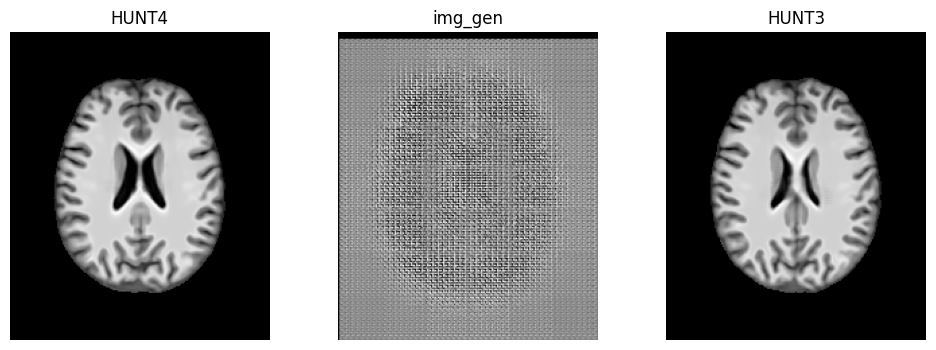

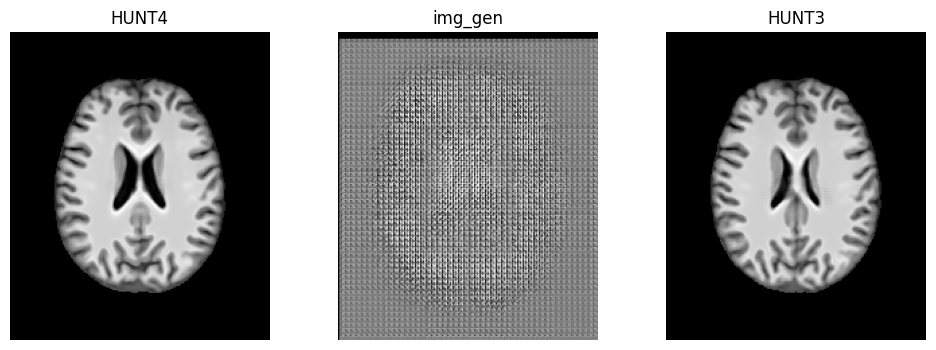

Initializing...:   0%|          | 0/91 [00:00<?, ?it/s]/cluster/home/agustinc/miniconda3/envs/s4_old/lib/python3.9/site-packages/tensorflow/python/framework/tensor_util.py:437: RuntimeWarning: overflow encountered in cast
  nparray = values.astype(dtype.as_numpy_dtype)


: 

In [7]:

def train(num_epochs, batch_size, monitor_each=100, show=False):
    image_size = (193,229,193)
    patch_size= (64,64,64)
    patch_step = (32,32,32)

    # ---- Models
    D_h4 = Discriminator.MetamorphicDiscriminator()
    G_h4 = Generator.MetamorphicGenerator()

    D_h3 = Discriminator.MetamorphicDiscriminator()
    G_h3 = Generator.MetamorphicGenerator()

    # optimizers
    inital_lr = 1e-5
    g_h3_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_h3_optimizer = tf.keras.optimizers.Adam(inital_lr)

    g_h4_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_h4_optimizer = tf.keras.optimizers.Adam(inital_lr)
    
    g_h3_optimizer_monitor = udl.LearningRateMonitor(g_h3_optimizer, inital_lr, 0.5, 1e-10, 20, "loss")
    g_h4_optimizer_monitor = udl.LearningRateMonitor(g_h4_optimizer, inital_lr, 0.5, 1e-10, 20, "loss")
    d_h3_optimizer_monitor = udl.LearningRateMonitor(d_h3_optimizer, inital_lr, 0.5, 1e-10, 20, "loss")
    d_h4_optimizer_monitor = udl.LearningRateMonitor(d_h4_optimizer, inital_lr, 0.5, 1e-10, 20, "loss")

    # ---- Data
    server = True
    data_train = DataLoaderPatches(pil.INAME_PREPROCESSED,
                                   batch_size=batch_size, 
                                   image_size=image_size, 
                                   patch_size=patch_size,
                                   patch_step=patch_step,
                                   images_onmemory=1,
                                   shuffle_patches=True,
                                   channels_first=False,
                                   background_th=0.15,
                                   shuffle_images=True,
                                   nb_patients=620,
                                    shuffle_before_selecting=False,
                                    server=server,
                                    exclude_ids=["08202"],
                                    data_type=np.float32,
                                    image_sufix_seg_gmm=pil.INAME_SEGMENTATION_3.format("{0}", "{1}", "nii.gz"))
    
    # data_train.prepare_custom_patches("bmask", pil.INAME_BRAIN_MASK.format("{0}", "{1}", pil.REGISTRATION_TO_MNI))
    data_train.prepare_custom_patches("seg3", pil.INAME_SEGMENTATION.format("{0}", "{1}", 3, "nii.gz"), data_type=np.int32)
    # weights={"bg":0, "ext":0.5, "csf":1.5, "gm":1.5, "wm":1}

    # visualization
    nb_loss = 3
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)

    log_dir=f"{current_path}/models/logs/train"
    summary_writer = tf.summary.create_file_writer(log_dir)


    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(g_h3_optimizer=g_h3_optimizer,
                                     g_h4_optimizer=g_h4_optimizer,
                                    d_h3_optimizer=d_h3_optimizer,
                                    d_h4_optimizer=d_h4_optimizer,
                                    D_h3=D_h3,
                                    D_h4=D_h4,
                                    G_h3=G_h3,
                                    G_h4=G_h4)
    

    # restore checkpoint
    checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))
    # checkpoint.restore(f"{checkpoint_dir}ckpt-19")

    for epoch in range(0,num_epochs):

        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        if epoch == 0 and show:
            show_generated_image("08202", G_h4, G_h3, patch_size, patch_step, current_plane=116, show=show)
        
        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (h3_batch_3, h4_batch_3) in enumerate(data_train):
            h3_seg_3, h4_seg_3 = data_train.get_iter_custom_patches("seg3")
            h3_gmm, h4_gmm = data_train.get_iter_patient_gmm()

            h3_batch_2, h3_batch_1 = get_2_scales_reduction(h3_batch_3)
            h4_batch_2, h4_batch_1 = get_2_scales_reduction(h4_batch_3)

            h3_seg_2, h3_seg_1 = get_2_scales_reduction(h3_seg_3)
            h4_seg_2, h4_seg_1 = get_2_scales_reduction(h4_seg_3)

            h3_batch = (h3_batch_1, h3_batch_2, h3_batch_3)
            h4_batch = (h4_batch_1, h4_batch_2, h4_batch_3)
            h3_seg = (h3_seg_1, h3_seg_2, h3_seg_3)
            h4_seg = (h4_seg_1, h4_seg_2, h4_seg_3)

            d_loss, g_h4_loss, g_h3_loss = train_step(G_h3, D_h3, G_h4, D_h4, h3_batch, h4_batch, g_h3_optimizer, d_h3_optimizer, g_h4_optimizer, d_h4_optimizer, h3_seg, h4_seg, h3_gmm, h4_gmm)
            acum_loss_train.update((d_loss, g_h4_loss, g_h3_loss))
            loss_mean = acum_loss_train.get_mean()
            
            progress_bar.set_description(desc=f'd_loss: {loss_mean[0]:.5f} \t g_h4_loss: {loss_mean[1]:.5f} \t g_h3_loss: {loss_mean[2]:.5f} ')
            progress_bar.update(1)
        del progress_bar

            
        loss_mean = acum_loss_train.get_mean()

        g_h3_optimizer_monitor.on_epoch_end(loss_mean[2])
        g_h4_optimizer_monitor.on_epoch_end(loss_mean[1])
        d_h3_optimizer_monitor.on_epoch_end(loss_mean[0])
        d_h4_optimizer_monitor.on_epoch_end(loss_mean[0])


        if (epoch + 1) % monitor_each == 0:
            # ---- Check points
            checkpoint.save(file_prefix=checkpoint_prefix)

            # ---- visuqlize
            if show:
                show_generated_image("00046", G_h4, G_h3, patch_size, patch_step, current_plane=116, show=show)
            val_results = show_generated_image("08202", G_h4, G_h3, patch_size, patch_step, current_plane=116, show=show)

            # ---- tensorboard
            with summary_writer.as_default():
                tf.summary.scalar('d_loss', loss_mean[0], step=epoch)
                tf.summary.scalar('g_h4_loss', loss_mean[1], step=epoch)
                tf.summary.scalar('g_h3_loss', loss_mean[2], step=epoch)
                
                # images
                gen_image_h4 = np.expand_dims(np.expand_dims(val_results[2], axis=-1), axis=0)
                hunt4_vs_gen_h4 = np.expand_dims(np.stack([val_results[2], val_results[1], np.zeros_like(val_results[1])], axis=-1), axis=0)
                tf.summary.image("generated H4", gen_image_h4, step=epoch)
                tf.summary.image("R: Gen H4 - G: HUNT4", hunt4_vs_gen_h4, step=epoch)
        
                gen_image_h3 = np.expand_dims(np.expand_dims(val_results[3], axis=-1), axis=0)
                hunt3_vs_gen_h3 = np.expand_dims(np.stack([val_results[3], val_results[0], np.zeros_like(val_results[0])], axis=-1), axis=0)
                tf.summary.image("generated H3", gen_image_h3, step=epoch)
                tf.summary.image("R: Gen H3 - G: HUNT3", hunt3_vs_gen_h3, step=epoch)

train(num_epochs=100000, batch_size=1, monitor_each=10, show=True)

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]